# 03 · Out-of-fold 평가 및 논문 비교
각 검증 케이스는 그 케이스를 학습하지 않은 fold의 최종 모델로 예측합니다.
학습 종료 시 저장되는 전체 볼륨 validation 예측을 사용합니다. 추가 앙상블/후처리는 적용하지 않습니다.
클래스: RV=1(우심실), MLV=2(심근), LVC=3(좌심실). NSD tolerance=2mm.
케이스별 → 영역별 → fold별 평균을 계산합니다. 양쪽 모두 빈 영역은 NaN으로 제외합니다.
논문의 정확한 코드/분할/집계 세부 조건과의 동일성이 확인되지 않은 부분은 보고서에 남습니다.
전체 5-fold를 선택하지 않으면 부분 결과입니다. fold 0 점수를 논문 5-fold 평균과 동등하게 해석하지 않습니다.

In [1]:
from pathlib import Path
import sys, os, json, shlex, subprocess
sys.dont_write_bytecode = True
REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "nnunetv2").is_dir())
EXPERIMENT = REPO / "experiments/acdc"
sys.path.insert(0, str(EXPERIMENT / "scripts"))
for module_name in ("workflow", "download_data", "evaluate_regions"):
    loaded = sys.modules.get(module_name)
    if loaded is not None and Path(loaded.__file__).resolve().parent != EXPERIMENT / "scripts":
        raise RuntimeError("다른 실험 모듈이 로드되어 있습니다. 커널을 재시작하세요.")
from workflow import read_config, paths, guard, environment, model_dir
CONFIG = EXPERIMENT / "config.server.json"
if not CONFIG.exists():
    CONFIG = EXPERIMENT / "config.json"  # 로컬 기본 설정: 실행 비활성화
cfg = read_config(CONFIG)
print("Config:", CONFIG)
print("Execution enabled:", cfg["execution_enabled"])
print("Storage:", cfg["storage_root"])


Config: /root/nnUNet/experiments/acdc/config.server.json
Execution enabled: True
Storage: /root/acdc-data


## 평가 실행
서버에서 수행합니다. CSV와 JSON은 외부 storage_root/runs 아래에 저장됩니다.

In [2]:
from evaluate_regions import evaluate
cases, folds, comparison = evaluate(cfg)


NVIDIA GeForce RTX 3090 23.68 GiB


NiftiImageIO (0x8f03140): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient005_frame01.nii.gz has unexpected scales in sform

NiftiImageIO (0x8f03140): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient005_frame01.nii.gz has unexpected scales in sform



Fold 0: patient005_frame01
Fold 0: patient005_frame13
Fold 0: patient007_frame01
Fold 0: patient007_frame07


NiftiImageIO (0xa2e9190): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient005_frame13.nii.gz has unexpected scales in sform

NiftiImageIO (0xa2e9190): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient005_frame13.nii.gz has unexpected scales in sform

NiftiImageIO (0xa207660): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient007_frame01.nii.gz has unexpected scales in sform

NiftiImageIO (0xa207660): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient007_frame01.nii.gz has unexpected scales in sform

NiftiImageIO (0xa214710): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient007_frame07.nii.gz has unexpected scales in sform

NiftiImageIO (0xa214710): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient007_frame07.nii.gz has unexpected scales in sform

NiftiImageIO (0xa207660): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient010_frame01.nii.gz has unexpected scales in sform

NiftiImageIO (0xa207660): /root/acdc-data/nnUNet

Fold 0: patient010_frame01
Fold 0: patient010_frame13
Fold 0: patient020_frame01
Fold 0: patient020_frame11


NiftiImageIO (0xa207660): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient010_frame13.nii.gz has unexpected scales in sform

NiftiImageIO (0xa207660): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient010_frame13.nii.gz has unexpected scales in sform

NiftiImageIO (0xa207660): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient020_frame01.nii.gz has unexpected scales in sform

NiftiImageIO (0xa207660): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient020_frame01.nii.gz has unexpected scales in sform

NiftiImageIO (0xa207660): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient020_frame11.nii.gz has unexpected scales in sform

NiftiImageIO (0xa207660): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient020_frame11.nii.gz has unexpected scales in sform

NiftiImageIO (0xa3d1190): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient022_frame01.nii.gz has unexpected scales in sform

NiftiImageIO (0xa3d1190): /root/acdc-data/nnUNet

... (11 outputs left out)

NiftiImageIO (0xa3d1190): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient069_frame12.nii.gz has unexpected scales in sform

NiftiImageIO (0xa3d1190): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient069_frame12.nii.gz has unexpected scales in sform

NiftiImageIO (0xa3d1190): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient073_frame01.nii.gz has unexpected scales in sform

NiftiImageIO (0xa3d1190): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient073_frame01.nii.gz has unexpected scales in sform

NiftiImageIO (0xa3d1190): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient073_frame10.nii.gz has unexpected scales in sform

NiftiImageIO (0xa3d1190): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient073_frame10.nii.gz has unexpected scales in sform

NiftiImageIO (0xa3d1190): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient075_frame01.nii.gz has unexpected scales in sform

NiftiImageIO (0xa3d1190): /root/acdc-data/nnUNet

Fold 0: patient075_frame06
Fold 0: patient077_frame01
Fold 0: patient077_frame09
Fold 0: patient088_frame01


NiftiImageIO (0xa3d1190): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient077_frame01.nii.gz has unexpected scales in sform

NiftiImageIO (0xa3d1190): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient077_frame01.nii.gz has unexpected scales in sform

NiftiImageIO (0xa3d1190): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient077_frame09.nii.gz has unexpected scales in sform

NiftiImageIO (0xa3d1190): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient077_frame09.nii.gz has unexpected scales in sform

NiftiImageIO (0xa3d1190): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient088_frame01.nii.gz has unexpected scales in sform

NiftiImageIO (0xa3d1190): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient088_frame01.nii.gz has unexpected scales in sform

NiftiImageIO (0xa3d1190): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient088_frame12.nii.gz has unexpected scales in sform

NiftiImageIO (0xa3d1190): /root/acdc-data/nnUNet

Fold 0: patient088_frame12


## 결과 확인

In [3]:
import pandas as pd
from IPython.display import display
display(folds * 100)
display(pd.DataFrame({
    "metric": ["Dice (%)", "NSD (%)"],
    "paper_5fold": [91.54, 94.93],
    "this_run": [comparison["dice_percent"], comparison["nsd_percent"]],
}))
print("Complete 5-fold:", comparison["complete_5fold"])
print("Reports:", paths(cfg)["run"] / "reports")
print("Limitations:", comparison["limitations"])


,dice,nsd
fold,,
0,91.711817,95.05107


,metric,paper_5fold,this_run
0,Dice (%),91.54,91.711817
1,NSD (%),94.93,95.051070


Complete 5-fold: False
Reports: /root/acdc-data/runs/acdc-baseline-v1/reports
Limitations: Current-code ACDC baseline; 100 training patients / 200 ED-ES volumes. Official converter patient-grouped split (seed 1234); exact paper split and historical environment unverified. RTX3090 differs from paper A100.


## 검증 예측 시각화
평가가 끝난 케이스 중 전체 볼륨 평균 Dice가 낮은 쪽·중간·높은 쪽에서 기본 3개를 선택합니다. 좋은 결과만 선택하지 않으며, 아래 예시는 전체 성능을 대신하지 않습니다.

각 행은 **MRI / 정답 / 예측 / 정답과 다른 픽셀**입니다. 기본 슬라이스는 정답 심장 영역이 가장 넓은 z 슬라이스입니다. 제목의 Dice는 해당 슬라이스가 아니라 **전체 3D 영상의 클래스 평균**입니다.

`N_EXAMPLES`로 예시 수를, `CASE_IDS`로 특정 케이스를 지정할 수 있습니다. `SLICE_INDEX`를 지정하면 모든 예시에 해당 z 인덱스(0부터)를 사용합니다. 저장된 validation 예측을 읽기만 하며 추가 추론이나 이미지 파일 저장은 하지 않습니다. 방향 재정렬 없이 원본 voxel z 축으로 표시합니다.


,fold,case,dice_percent,nsd_percent
0,0,patient034_frame16,78.954481,76.034552
20,0,patient051_frame01,92.667917,98.102834
39,0,patient059_frame01,96.744691,99.656132


NiftiImageIO (0xa9d79b0): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient034_frame16.nii.gz has unexpected scales in sform

NiftiImageIO (0xa9d79b0): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient034_frame16.nii.gz has unexpected scales in sform

NiftiImageIO (0xa9d79b0): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/imagesTr/patient034_frame16_0000.nii.gz has unexpected scales in sform

NiftiImageIO (0xa9d79b0): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/imagesTr/patient034_frame16_0000.nii.gz has unexpected scales in sform

NiftiImageIO (0xac6d8d0): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient034_frame16.nii.gz has unexpected scales in sform

NiftiImageIO (0xac6d8d0): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient034_frame16.nii.gz has unexpected scales in sform



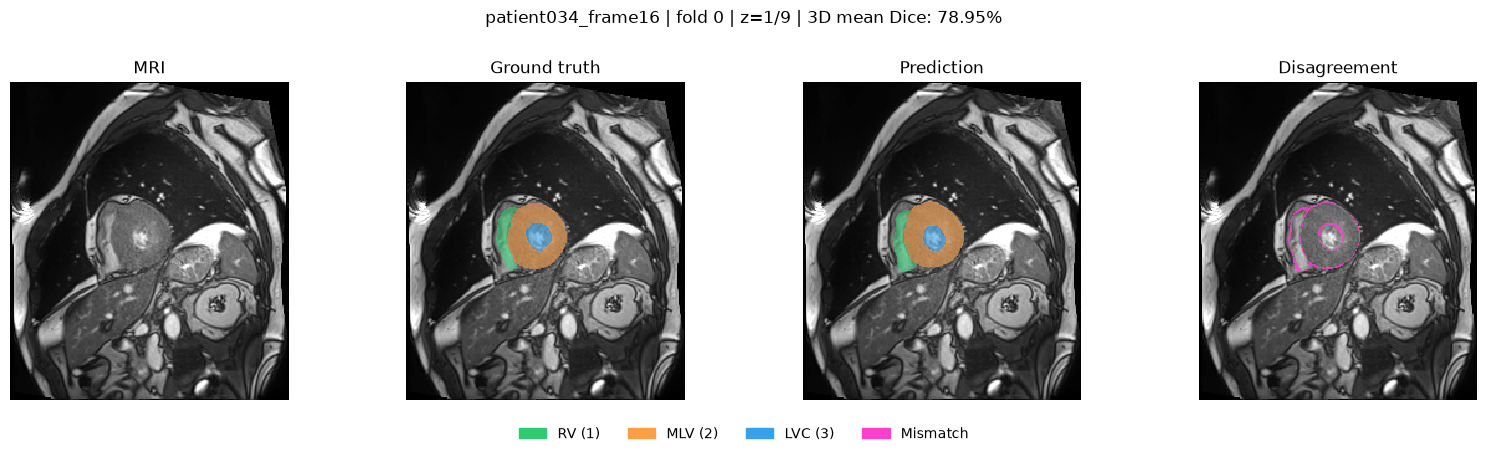

NiftiImageIO (0xaaf9190): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient051_frame01.nii.gz has unexpected scales in sform

NiftiImageIO (0xaaf9190): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient051_frame01.nii.gz has unexpected scales in sform

NiftiImageIO (0xaaf9190): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/imagesTr/patient051_frame01_0000.nii.gz has unexpected scales in sform

NiftiImageIO (0xaaf9190): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/imagesTr/patient051_frame01_0000.nii.gz has unexpected scales in sform

NiftiImageIO (0xa9d79b0): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient051_frame01.nii.gz has unexpected scales in sform

NiftiImageIO (0xa9d79b0): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient051_frame01.nii.gz has unexpected scales in sform



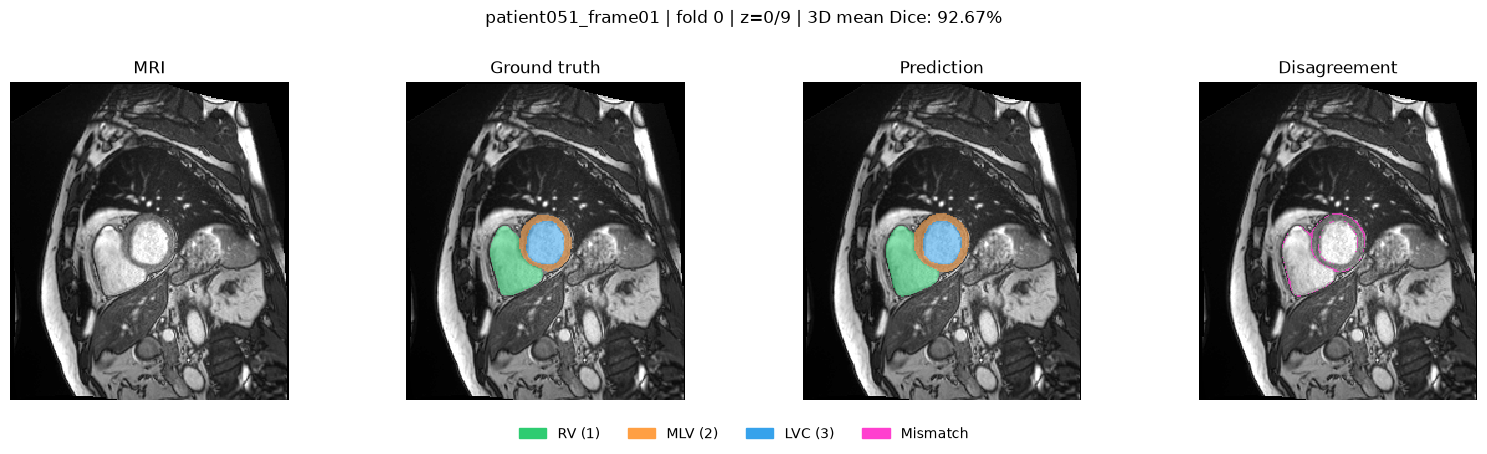

NiftiImageIO (0xa4cb440): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient059_frame01.nii.gz has unexpected scales in sform

NiftiImageIO (0xa4cb440): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient059_frame01.nii.gz has unexpected scales in sform

NiftiImageIO (0xa4cb440): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/imagesTr/patient059_frame01_0000.nii.gz has unexpected scales in sform

NiftiImageIO (0xa4cb440): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/imagesTr/patient059_frame01_0000.nii.gz has unexpected scales in sform

NiftiImageIO (0xa527de0): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient059_frame01.nii.gz has unexpected scales in sform

NiftiImageIO (0xa527de0): /root/acdc-data/nnUNet_raw/Dataset027_ACDC/labelsTr/patient059_frame01.nii.gz has unexpected scales in sform



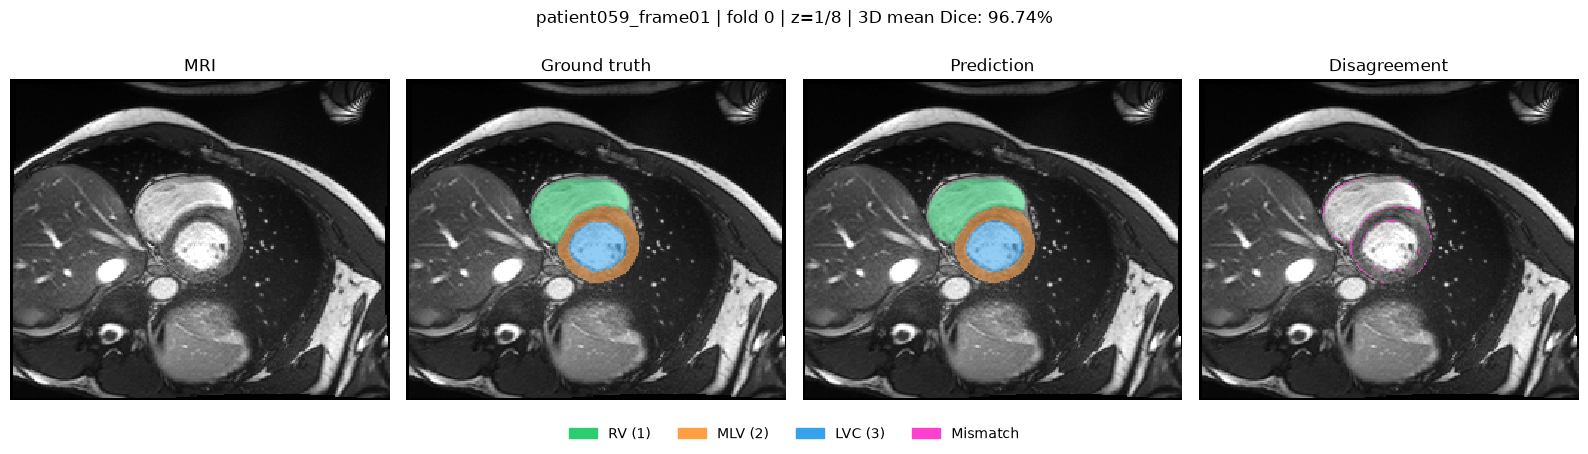

In [4]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap, BoundaryNorm
from matplotlib.patches import Patch
from evaluate_regions import read_masks

N_EXAMPLES = 3
CASE_IDS = []  # 예: ["patient005_frame01", "patient005_frame13"]
SLICE_INDEX = None  # None: 정답 영역이 가장 넓은 슬라이스

scores = (cases.groupby(["fold", "case"], as_index=False)[["dice", "nsd"]]
          .mean().sort_values(["dice", "case"], na_position="last").reset_index(drop=True))
if scores.empty:
    raise ValueError("앞의 평가 셀을 실행하여 검증 결과를 먼저 생성하세요.")
if CASE_IDS:
    missing = set(CASE_IDS) - set(scores["case"])
    if missing:
        raise ValueError(f"평가한 검증 케이스에 없습니다: {sorted(missing)}")
    selected = scores.set_index("case").loc[list(dict.fromkeys(CASE_IDS))].reset_index()
else:
    if not isinstance(N_EXAMPLES, int) or N_EXAMPLES < 1:
        raise ValueError("N_EXAMPLES는 1 이상의 정수여야 합니다.")
    indices = np.linspace(0, len(scores) - 1, min(N_EXAMPLES, len(scores))).round().astype(int)
    selected = scores.iloc[indices]

display(selected.assign(dice_percent=selected["dice"] * 100,
                        nsd_percent=selected["nsd"] * 100)[
                            ["fold", "case", "dice_percent", "nsd_percent"]])
colors = ["#2ecc71", "#ff9f43", "#36a2eb"]
label_cmap = ListedColormap(colors)
label_norm = BoundaryNorm([0.5, 1.5, 2.5, 3.5], label_cmap.N)
root = paths(cfg)["raw"] / cfg["dataset_name"]

for row in selected.itertuples(index=False):
    label_path = root / "labelsTr" / f"{row.case}.nii.gz"
    prediction_path = model_dir(cfg) / f"fold_{row.fold}" / "validation" / f"{row.case}.nii.gz"
    gt, pred, spacing = read_masks(label_path, prediction_path)
    image, _, _ = read_masks(root / "imagesTr" / f"{row.case}_0000.nii.gz", label_path)
    if not np.isin(gt, [0, 1, 2, 3]).all() or not np.isin(pred, [0, 1, 2, 3]).all():
        raise ValueError(f"Unexpected labels: {row.case}")
    z = int(np.argmax(np.count_nonzero(gt, axis=(1, 2)))) if SLICE_INDEX is None else SLICE_INDEX
    if not isinstance(z, (int, np.integer)) or not 0 <= z < image.shape[0]:
        raise ValueError(f"{row.case}: SLICE_INDEX는 0~{image.shape[0] - 1} 범위여야 합니다.")
    plane = image[z]
    finite = plane[np.isfinite(plane)]
    if not finite.size:
        raise ValueError(f"{row.case}: 표시 가능한 유한한 영상 값이 없습니다.")
    low, high = np.percentile(finite, [1, 99])
    if high <= low:
        high = low + 1
    # Arrays are z,y,x; preserve physical in-plane proportions.
    aspect = spacing[1] / spacing[2]
    fig, axes = plt.subplots(1, 4, figsize=(16, 4.5))
    try:
        for ax, title in zip(axes, ["MRI", "Ground truth", "Prediction", "Disagreement"]):
            ax.imshow(plane, cmap="gray", vmin=low, vmax=high, aspect=aspect,
                      interpolation="nearest")
            ax.set_title(title)
            ax.axis("off")
        for ax, mask in [(axes[1], gt[z]), (axes[2], pred[z])]:
            ax.imshow(np.ma.masked_equal(mask, 0), cmap=label_cmap, norm=label_norm,
                      alpha=0.55, aspect=aspect, interpolation="nearest")
        error = gt[z] != pred[z]
        axes[3].imshow(np.ma.masked_where(~error, np.ones_like(error, dtype=float)),
                       cmap=ListedColormap(["#ff3fcf"]), vmin=0, vmax=1,
                       alpha=0.75, aspect=aspect, interpolation="nearest")
        fig.suptitle(f"{row.case} | fold {row.fold} | z={z}/{image.shape[0]-1} | "
                     f"3D mean Dice: {row.dice * 100:.2f}%")
        fig.legend(handles=[Patch(color=color, label=label) for color, label in
                            zip(colors + ["#ff3fcf"], ["RV (1)", "MLV (2)", "LVC (3)", "Mismatch"])],
                   loc="lower center", ncol=4, frameon=False)
        fig.tight_layout(rect=(0, 0.08, 1, 0.93))
        plt.show()
    finally:
        plt.close(fig)
